# Raport Laboratorik — Elektronika (LAB 03)

**Tema:** Matjet me Oshiloskop dhe Qarqet RC  
**Punoi:** Jonida Klari  
**Data e punimit:** 21.11.2026  
**Data e dorëzimit:** 21.11.2026  

---

## 1. Qëllimi i Punës Laboratorike
Qëllimi i këtij eksperimenti është përdorimi i **oshiloskopit** për matjen e karakteristikave kohore dhe frekuencore të sinjaleve periodike (periodës $T$ dhe frekuencës $f$) për 4 kondesatorë të ndryshëm, si dhe analizimi i sjelljes së **qarqeve RC** në regjim të ndryshueshëm.

## 2. Bazat Teorike
* **Perioda ($T$) dhe Frekuenca ($f$):** Për një sinjal periodik të vëzhguar në ekranin e oshiloskopit, perioda $T$ (në sekonda) është koha e një cikli të plotë, ndërsa frekuenca $f$ (në Hz) jepet nga relacioni:
  $$f = \frac{1}{T}$$
* **Konstantja Kohore në Qarqet RC ($\tau$):** Në një qark të përbërë nga një rezistor $R$ dhe një kondesator $C$, shpejtësia e ngarkimit dhe shkarkimit të kondesatorit përcaktohet nga konstantja kohore:
  $$\tau = R \cdot C$$
* **Matja me Oshiloskop:** Duke rregulluar bazën e kohës (*Time/Div*) dhe ndjeshmërinë e tensionit (*Volts/Div*), lexohet numri i ndarjeve horizontale për një periodë të plotë dhe llogaritet $T$ dhe $f$.

## 3. Të Dhënat Eksperimentale dhe Tabela
Tabela më poshtë paraqet të dhënat e regjistruara nga skedari `tabela e eksperimenteve.csv` për 4 kondesatorët e testuar.

In [5]:
from IPython.display import HTML, display

kondesatori = [1, 2, 3, 4]
t_s = ["3e-6", "6e-6", "2e-6", "1e-6"]
f_hz = ["110.7 kHz", "333.3 kHz", "300 kHz", "1 MHz"]

rows_html = ""
for c, t, f in zip(kondesatori, t_s, f_hz):
  rows_html += f"<tr><td>{c}</td><td>{t}</td><td>{f}</td></tr>"

html_table = f"""
<table border="1" cellpadding="6" style="border-collapse: collapse; text-align: center; font-family: Arial, sans-serif;">
  <tr style="background-color: #f2f2f2;">
    <th>Kondesator (C)</th>
    <th>T (s)</th>
    <th>f (Hz)</th>
  </tr>
  {rows_html}
</table>
"""

display(HTML(html_table))

Kondesator (C),T (s),f (Hz)
1,3e-6,110.7 kHz
2,6e-6,333.3 kHz
3,2e-6,300 kHz
4,1e-6,1 MHz


## 4. Vizualizimi Grafik i Rezultateve
Më poshtë paraqiten të dy grafikët në një figurë të vetme: **Perioda $T$ ($\mu\text{s}$)** dhe **Frekuenca $f$ ($\text{kHz}$)** për secilin kondesator.

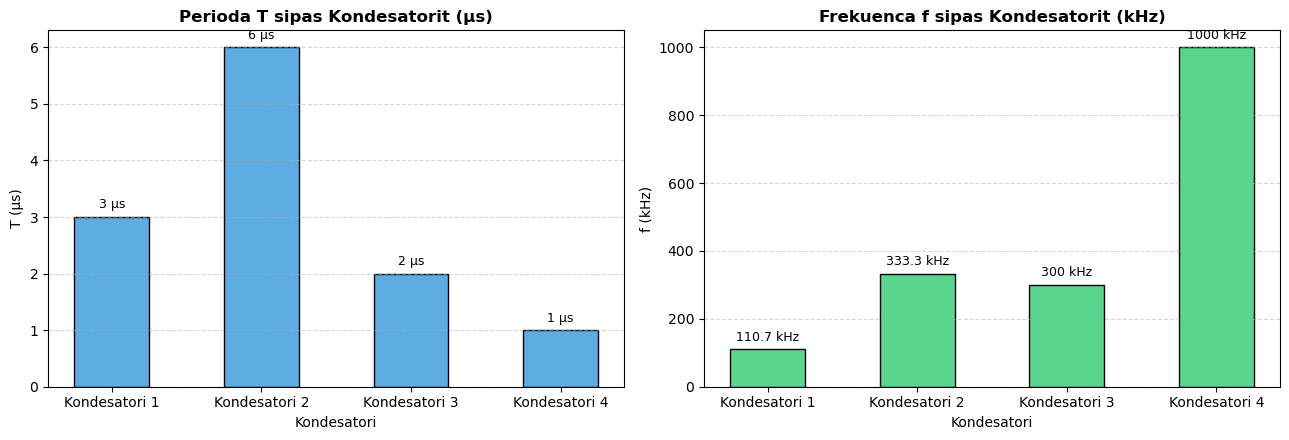

In [6]:
import matplotlib.pyplot as plt

kondesatori = [
    "Kondesatori 1",
    "Kondesatori 2",
    "Kondesatori 3",
    "Kondesatori 4",
]
t_us = [3.0, 6.0, 2.0, 1.0]  # T (s) në mikrosekonda (µs): 3e-6, 6e-6, 2e-6, 1e-6
f_khz = [
    110.7,
    333.3,
    300.0,
    1000.0,
]  # f në kHz: 110.7 kHz, 333.3 kHz, 300 kHz, 1 MHz = 1000 kHz

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bars_t = axes[0].bar(
    kondesatori, t_us, color="#5DADE2", edgecolor="black", width=0.5
)
axes[0].set_title("Perioda T sipas Kondesatorit (µs)", fontweight="bold")
axes[0].set_xlabel("Kondesatori")
axes[0].set_ylabel("T (µs)")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
for bar, val in zip(bars_t, t_us):
  axes[0].annotate(
      f"{val:g} µs",
      xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
      xytext=(0, 4),
      textcoords="offset points",
      ha="center",
      va="bottom",
      fontsize=9,
  )

bars_f = axes[1].bar(
    kondesatori, f_khz, color="#58D68D", edgecolor="black", width=0.5
)
axes[1].set_title("Frekuenca f sipas Kondesatorit (kHz)", fontweight="bold")
axes[1].set_xlabel("Kondesatori")
axes[1].set_ylabel("f (kHz)")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
for bar, val in zip(bars_f, f_khz):
  axes[1].annotate(
      f"{val:g} kHz",
      xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
      xytext=(0, 4),
      textcoords="offset points",
      ha="center",
      va="bottom",
      fontsize=9,
  )

plt.tight_layout()
plt.show()

## 5. Analiza e Gabimeve
* **Pasiguria e leximit në ekranin e oshiloskopit:** Leximi vizual i ndarjeve horizontale (*Time/Div*) dhe pozicionimi i kursorëve sjell pasiguri të vogla në përcaktimin e saktë të periodës $T$.
* **Mospërputhja mes $T$ së matur dhe $f$ së regjistruar:** Teorikisht $f = 1/T$ (p.sh., për $T = 1\times 10^{-6}\text{ s}$, $f = 1\text{ MHz}$, dhe për $T = 2\times 10^{-6}\text{ s}$, $f = 500\text{ kHz}$ kundrejt $300\text{ kHz}$ të matur; për $T = 3\times 10^{-6}\text{ s}$, $f = 333.3\text{ kHz}$ kundrejt $110.7\text{ kHz}$ të matur). Këto devijime tregojnë ndryshime të bazës kohore (*Time/Div*), leximit të kursorëve ose kapaciteteve parazitare të sondës dhe *breadboard*-it.
* **Toleranca e kondesatorëve dhe kapacitetet parazitare:** Kondesatorët realë kanë tolerancë prodhimi ($\pm 5\%$ deri në $\pm 20\%$), ndërsa telat lidhës dhe sonda e oshiloskopit shtojnë kapacitet parazitar që ndikon sidomos në frekuenca të larta (rreth $1\text{ MHz}$).

## 6. Diskutimi
* **Krahasimi mes 4 kondesatorëve:** Nga të dhënat e matura shihet se vlerat e periodës variojnë nga $T = 1\times 10^{-6}\text{ s}$ ($1\,\mu\text{s}$) te Kondesatori 4 deri në $T = 6\times 10^{-6}\text{ s}$ ($6\,\mu\text{s}$) te Kondesatori 2.
* **Sjellja në frekuencë:** Kondesatori 4 ka periodën më të shkurtër ($1\,\mu\text{s}$) dhe frekuencën më të lartë ($1\text{ MHz}$), duke konfirmuar se një konstante kohore $\tau = RC$ më e vogël çon në ngarkim/shkarkim më të shpejtë dhe frekuencë më të lartë të sinjalit.

## 7. Përfundimi
* Eksperimenti mundësoi matjen e periodës $T$ dhe frekuencës $f$ me oshiloskop për katër kondesatorë të ndryshëm në qarqet RC.
* U vërejt se me zvogëlimin e periodës (nga $6\,\mu\text{s}$ në $1\,\mu\text{s}$), frekuenca e sinjalit rritet deri në $1\text{ MHz}$.
* Dokumentimi i matjeve në `tabela_e_eksperimenteve.csv` dhe përpunimi grafik në `raportin.ipynb` lehtësuan krahasimin e rezultateve dhe identifikimin e burimeve të gabimeve. 